In [ ]:
#8ai and ii
import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

print(df.shape)
print(df.head())

#preprocessing
df = df[[
    "age", "studytime", "schoolsup", "goout",
    "Dalc", "Walc", "health", "absences", "G3"
]].copy()

df["schoolsup"] = df["schoolsup"].map({"no": 0, "yes": 1})
df["alc"] = (df["Dalc"] + df["Walc"]) / 2
df = df.drop(columns=["Dalc", "Walc"])

print(df.head())

#8aiii number of outliers 
#dropping target var
X = df.drop(columns=["G3"])
y = df["G3"]

outlier_counts = {}

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = (X[col] < lower) | (X[col] > upper)
    outlier_counts[col] = outliers.sum()

outlier_df = pd.DataFrame(
    outlier_counts.items(),
    columns=["Feature", "Outlier Count"])
print(outlier_df)


(395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
   age  studytime  schoolsup  goout  health  absences  G3  alc
0   18         

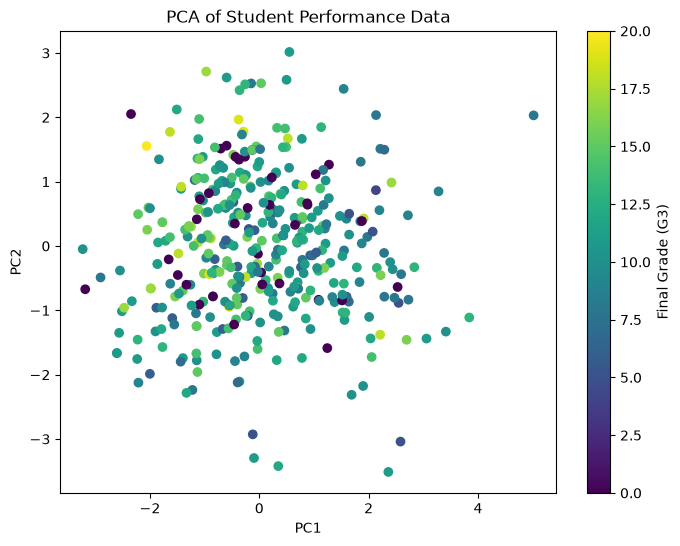

Explained variance: [0.23675738 0.17136598]
Total explained variance: 0.4081233589507941
                PC1       PC2
age        0.381940  0.589260
studytime -0.329734  0.385671
schoolsup -0.248184 -0.464202
goout      0.493755 -0.139613
health     0.080545 -0.400925
absences   0.280106  0.182798
alc        0.595871 -0.273677


In [4]:
#8a iv PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#standardizing IVs 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#plots PC1 vs PC2
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Student Performance Data")
plt.colorbar(label="Final Grade (G3)")
plt.show()

#results 
print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

#feature contributions
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"])
print(loadings)

#8aiv interpretation
PC1 accounts for explaining 23.67% of the variance, whereas PC2 explains 17.13% of the variance. Together, they account for approximately 40.81% of the total variance. The strongest contributors appear to be alc, goouat, and age for PC1 while PC2 seems to have age, schoolsup, and health being the greatest contributors. The scatterplot illustrates overlap for students in final grades (G3, our target variable), while there is not a clear separation by grade. 

In [6]:
#8bi train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=552)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

#8b ii regression models (linear, ridge, lasso)
from sklearn.linear_model import LinearRegression, Ridge, Lasso

#linear
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
#ridge 
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train, y_train)
#lasso 
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)

Training set: (316, 7)
Testing set: (79, 7)


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [7]:
#8biii model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model}
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2"] )
print(results_df)

               Model       MAE      RMSE        R2
0  Linear Regression  3.418009  4.755812  0.028177
1              Ridge  3.418062  4.755859  0.028157
2              Lasso  3.447073  4.793840  0.012573


#8b iii interpretation
The linear regression had the lowest MAE of 3.4180, lowest RSME of 4.755812, and the highest R squared of 0.028177. The ridge regression had very similar and close results and the lasso performed the worst (relatively). It is among the R squared that the three models illustrated to have limited predictable ability for the final grades. In conclusion, the linear regression performed best across the three metrics. 

#8 iv interpretation of R squared values 
For all three models, the R squared values are low. This leaves the explaination of the independent variables explaining a small part of the variation in final grades. The linear and ridge regression explain roughly 2.82% of the variation, while the lasso model explains 1.26%. In conclusion, the selected features appear to have limited predictive power, therefore more relevant variables might have to be researched in order to improve model performance/predictive ability. 

In [8]:
# 8b vprinting coefficients
coefficients_df = pd.DataFrame({
    "Feature": X.columns,
    "Linear Regression": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_ })
print(coefficients_df)

     Feature  Linear Regression     Ridge     Lasso
0        age          -0.781077 -0.780739 -0.630377
1  studytime           0.444812  0.444655  0.349092
2  schoolsup          -0.682472 -0.682191 -0.547461
3      goout          -0.582519 -0.582312 -0.485602
4     health          -0.243324 -0.243227 -0.141569
5   absences           0.192800  0.192695  0.072043
6        alc           0.037073  0.036909 -0.000000


#8b vi what's the relationship between each IV and DV? 
The relationship between age, schoolsup, goout, and health (the dependent variables) have a negative relationship with G3(the independent variable). Whereas studytime, absences, and alc have positive relationships with the final grades. In the linear regression model, age has the largest negative coefficient of -0.781077. In contrast, studytime has the highest positive coefficient of 0.4448. Alcohol consumption was the closest to zero at 0.037073. In conclusion, these relationships seem to illustrate associations rather than proving strong causation. 

#8b vii regualarization methods differ? conclusion
The ridge regularization utilizes L2 regularization in order to shrink the coefficients to zero. The lasso regularization utilizes L1 regularization, and in doing so can get rid of less influential features by setting the coefficients to zero. With this particular dataset, the ridge regression produced coefficients and performance metrics almost identical to linear regression. This alludes to how regularization gave little improvement. Lasso did reduce the alcohol coefficient to zero, which means this variable contributed little information. In conclusion, the low R squared values imply that the chosen features have limited predicting ability for final grades (G3). 

#8b viii increasing alpha 
If the regularization strength is increased (the alpha), the regularization becomes stronger, creating the regression coefficients to shrink toward zero. In lasso regression, more coefficients could be zero, while in ridge regression the coefficients get smaller. Increasing the alpha could help by reducing overfitting. But on the other hand, if the alpha were to increase too much, the models would begin to underfit the data. As the results show no improvement at alpha equalling 0.1, increasing the alpha might continue to reduce predictive performance(though this is merely a hypothesis).

#8b ix feature engineering methods for improvement
Some feature engineering methods I would suggest would be to include past grades for precedent. In addition, considering interaction terms may be helpful (like studytime and absences, or absences and alc). This would ideally provide better understanding of how the relationship between one variable and G3 changes, when its dependent on another variable. 